## Homework 2. Machine Learning for Regression

In [1]:
import pandas as pd
import numpy as np

## Dataset

In [2]:
data = 'https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv'

In [3]:
# !wget $data
# Pinned 2026 release is also available locally in the course repository
data = '../cohorts/2026/data/car_fuel_efficiency_2026.csv'

In [4]:
df = pd.read_csv(data)

In [5]:
df.head()

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,2006,Europe,Gasoline,Front-wheel drive,4,2180,6,243.0,3870,NaN,31.9
1,2008,Europe,Diesel,Front-wheel drive,4,2390,6,272.0,4210,NaN,31.3
2,1996,Asia,Gasoline,Front-wheel drive,5,2320,6,267.0,4240,17.3,27.5
3,1989,Europe,Gasoline,Front-wheel drive,4,2130,6,258.0,4490,18.7,28.5
4,1994,USA,Diesel,Front-wheel drive,3,2580,7,304.0,4510,17.5,31.0


## Preparing the dataset

In [6]:
columns = [
    'engine_displacement',
    'horsepower',
    'vehicle_weight',
    'model_year',
    'fuel_efficiency_mpg',
]

df = df[columns]

In [7]:
df.head()

,engine_displacement,horsepower,vehicle_weight,model_year,fuel_efficiency_mpg
0,2180,243.0,3870,2006,31.9
1,2390,272.0,4210,2008,31.3
2,2320,267.0,4240,1996,27.5
3,2130,258.0,4490,1989,28.5
4,2580,304.0,4510,1994,31.0


In [8]:
len(df)

10000

## EDA

In [9]:
import matplotlib.pyplot as plt

%matplotlib inline

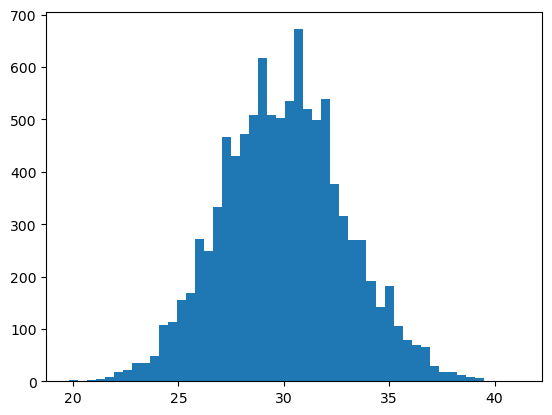

In [10]:
plt.hist(df.fuel_efficiency_mpg, bins=50)
plt.show()

In [11]:
df.fuel_efficiency_mpg.describe()

count    10000.000000
mean        29.997700
std          2.930245
min         19.800000
25%         28.000000
50%         30.000000
75%         31.900000
max         41.200000
Name: fuel_efficiency_mpg, dtype: float64

In [12]:
df.fuel_efficiency_mpg.skew()

0.08080419601878173

## Question 1

There's one column with missing values. What is it?

In [13]:
df.isnull().sum()

engine_displacement      0
horsepower             877
vehicle_weight           0
model_year               0
fuel_efficiency_mpg      0
dtype: int64

## Question 2

What's the median (50% percentile) for variable `'horsepower'`?

In [14]:
df.horsepower.median()

254.0

In [15]:
df.horsepower.describe()

count    9123.000000
mean      254.446016
std        22.844613
min       171.000000
25%       239.000000
50%       254.000000
75%       270.000000
max       334.000000
Name: horsepower, dtype: float64

## Prepare and split the dataset

In [16]:
def split_data(df, seed):
    n = len(df)
    n_val = int(n * 0.2)
    n_test = int(n * 0.2)
    n_train = n - n_val - n_test

    np.random.seed(seed)
    idx = np.arange(n)
    np.random.shuffle(idx)

    df_train = df.iloc[idx[:n_train]]
    df_val = df.iloc[idx[n_train:n_train + n_val]]
    df_test = df.iloc[idx[n_train + n_val:]]

    df_train = df_train.reset_index(drop=True)
    df_val = df_val.reset_index(drop=True)
    df_test = df_test.reset_index(drop=True)

    y_train = df_train.fuel_efficiency_mpg.values
    y_val = df_val.fuel_efficiency_mpg.values
    y_test = df_test.fuel_efficiency_mpg.values

    del df_train['fuel_efficiency_mpg']
    del df_val['fuel_efficiency_mpg']
    del df_test['fuel_efficiency_mpg']

    return df_train, df_val, df_test, y_train, y_val, y_test

In [17]:
df_train, df_val, df_test, y_train, y_val, y_test = split_data(df, seed=42)

In [18]:
len(df_train), len(df_val), len(df_test)

(6000, 2000, 2000)

## Linear regression

In [19]:
def train_linear_regression(X, y):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)
    
    return w_full[0], w_full[1:]

In [20]:
def train_linear_regression_reg(X, y, r=0.001):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX = XTX + r * np.eye(XTX.shape[0])

    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)
    
    return w_full[0], w_full[1:]

In [21]:
def rmse(y, y_pred):
    se = (y - y_pred) ** 2
    mse = se.mean()
    return np.sqrt(mse)

In [22]:
base = ['engine_displacement', 'horsepower', 'vehicle_weight', 'model_year']

def prepare_X(df, fill_value=0):
    df_num = df[base]
    df_num = df_num.fillna(fill_value)
    X = df_num.values
    return X

## Question 3

Fill missing `horsepower` with 0 or with the mean (computed on train only). Which option gives better RMSE?

Option 1: fill with 0

In [23]:
X_train = prepare_X(df_train, fill_value=0)
w0, w = train_linear_regression(X_train, y_train)

X_val = prepare_X(df_val, fill_value=0)
y_pred = w0 + X_val.dot(w)

score_zero = round(rmse(y_val, y_pred), 3)
score_zero

2.205

Option 2: fill with mean

In [24]:
mean_hp = df_train.horsepower.mean()
mean_hp

254.46338337605272

In [25]:
X_train = prepare_X(df_train, fill_value=mean_hp)
w0, w = train_linear_regression(X_train, y_train)

X_val = prepare_X(df_val, fill_value=mean_hp)
y_pred = w0 + X_val.dot(w)

score_mean = round(rmse(y_val, y_pred), 3)
score_mean

2.202

In [26]:
score_zero, score_mean

(2.205, 2.202)

## Question 4

Regularized linear regression, NAs filled with 0. Which `r` gives the best RMSE?

In [27]:
X_train = prepare_X(df_train, fill_value=0)
X_val = prepare_X(df_val, fill_value=0)

scores = {}

for r in [0, 0.01, 0.1, 1, 5, 10, 100]:
    w0, w = train_linear_regression_reg(X_train, y_train, r=r)
    y_pred = w0 + X_val.dot(w)
    score = round(rmse(y_val, y_pred), 4)
    scores[r] = score
    print(r, w0, score)

0 -153.8849618823138 2.2053
0.01 -148.3092124404723 2.2058
0.1 -111.83871039306318 2.2241
1 -32.331865964971264 2.3492
5 -7.7728522099734025 2.4094
10 -3.9871164160193766 2.4195
100 -0.40821964884790385 2.4292


In [28]:
best_score = min(scores.values())
best_r = min(r for r, s in scores.items() if s == best_score)
best_r, best_score

(0, 2.2053)

## Question 5

How does the seed influence the score? Standard deviation of RMSE across seeds 0-9.

In [29]:
rmse_scores = []

for seed in [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]:
    df_train, df_val, df_test, y_train, y_val, y_test = split_data(df, seed=seed)

    X_train = prepare_X(df_train, fill_value=0)
    w0, w = train_linear_regression(X_train, y_train)

    X_val = prepare_X(df_val, fill_value=0)
    y_pred = w0 + X_val.dot(w)

    score = rmse(y_val, y_pred)
    rmse_scores.append(score)
    print(seed, score)

0 2.239204143046126
1 2.2021128210838845
2 2.1634197787530947
3 2.2043588768539224
4 2.2018800943311554
5 2.2457851509085134
6 2.2697212079524043
7 2.190794599933443
8 2.216611201686444
9 2.2070365928178957


In [30]:
round(np.std(rmse_scores), 3)

0.029

## Question 6

Split with seed 9, combine train and validation, fill NAs with 0, train with `r=0.001`. RMSE on test?

In [31]:
df_train, df_val, df_test, y_train, y_val, y_test = split_data(df, seed=9)

In [32]:
df_full_train = pd.concat([df_train, df_val])
df_full_train = df_full_train.reset_index(drop=True)

y_full_train = np.concatenate([y_train, y_val])

In [33]:
X_full_train = prepare_X(df_full_train, fill_value=0)
w0, w = train_linear_regression_reg(X_full_train, y_full_train, r=0.001)

X_test = prepare_X(df_test, fill_value=0)
y_pred = w0 + X_test.dot(w)

score = rmse(y_test, y_pred)
score

2.235827747191731

In [34]:
round(score, 3)

2.236